In [4]:

import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.layers import (
    Input, Conv1D, MaxPooling1D,
    GlobalAveragePooling1D,
    BatchNormalization, ReLU,
    Dense, Dropout,
    Multiply, Concatenate,
    GlobalMaxPooling1D,
    Reshape, Layer
)

from tensorflow.keras.models import Model

from tensorflow.keras.utils import to_categorical

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from sklearn.utils.class_weight import compute_class_weight


# ============================================================
# 1. SEED
# ============================================================

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)


# ============================================================
# 2. CONFIGURATION
# ============================================================

DATA_PATH = "/content/drive/MyDrive/Colab Notebooks/WISDM_ar_v1.1_raw.txt"

MODEL_PATH = "/content/best_inception_se_cbam.keras"

WINDOW_SIZE = 128
STRIDE = 64

N_CHANNELS = 3
N_CLASSES = 6

TIME_GAP_THRESHOLD = 200_000_000

BATCH_SIZE = 64
EPOCHS = 50

LEARNING_RATE = 0.0003

class_names = [
    "WALKING",
    "JOGGING",
    "UPSTAIRS",
    "DOWNSTAIRS",
    "SITTING",
    "STANDING"
]

activity_map = {
    "Walking": 0,
    "Jogging": 1,
    "Upstairs": 2,
    "Downstairs": 3,
    "Sitting": 4,
    "Standing": 5
}


# ============================================================
# 3. LOAD WISDM DATASET
# ============================================================

def load_wisdm(path):

    columns = [
        "user",
        "activity",
        "timestamp",
        "x",
        "y",
        "z"
    ]

    df = pd.read_csv(
        path,
        header=None,
        names=columns,
        sep=",",
        engine="python",
        on_bad_lines="skip",
        skipinitialspace=True
    )

    df["z"] = (
        df["z"]
        .astype(str)
        .str.replace(";", "", regex=False)
    )

    for col in ["user", "timestamp", "x", "y", "z"]:

        df[col] = pd.to_numeric(
            df[col],
            errors="coerce"
        )

    df["activity"] = (
        df["activity"]
        .astype(str)
        .str.strip()
    )

    df = df.dropna(
        subset=columns
    ).copy()

    df["user"] = df["user"].astype(int)

    df["timestamp"] = df["timestamp"].astype(np.int64)

    df = df[
        df["activity"].isin(activity_map.keys())
    ].copy()

    df["label"] = (
        df["activity"]
        .map(activity_map)
        .astype(int)
    )

    df = df.sort_values(
        ["user", "timestamp"]
    ).reset_index(drop=True)

    return df


df = load_wisdm(DATA_PATH)

print("Dataset shape:", df.shape)

print("Number of users:", df["user"].nunique())

print("\nActivity distribution:")

print(df["activity"].value_counts())


# ============================================================
# 4. TIMESTAMP CHECK
# ============================================================

timestamp_diff = (
    df.groupby("user")["timestamp"].diff()
)

print("\nTimestamp statistics:")

print(timestamp_diff.describe())


# ============================================================
# 5. SUBJECT-WISE SPLIT
# ============================================================

users = np.sort(df["user"].unique())

rng = np.random.RandomState(SEED)

rng.shuffle(users)

n_users = len(users)

n_train = int(n_users * 0.70)

n_val = int(n_users * 0.15)

train_users = users[:n_train]

val_users = users[
    n_train:n_train + n_val
]

test_users = users[
    n_train + n_val:
]

print("\nTrain users:", train_users)

print("Validation users:", val_users)

print("Test users:", test_users)


assert len(set(train_users) & set(val_users)) == 0

assert len(set(train_users) & set(test_users)) == 0

assert len(set(val_users) & set(test_users)) == 0


# ============================================================
# 6. SPLIT DATASET
# ============================================================

train_df = df[
    df["user"].isin(train_users)
].copy()

val_df = df[
    df["user"].isin(val_users)
].copy()

test_df = df[
    df["user"].isin(test_users)
].copy()


for name, split_df in [
    ("TRAIN", train_df),
    ("VALIDATION", val_df),
    ("TEST", test_df)
]:

    print(f"\n{name} activity distribution:")

    print(split_df["activity"].value_counts())


# ============================================================
# 7. SLIDING WINDOW GENERATION
# ============================================================

def create_windows(
    data,
    window_size=128,
    stride=64
):

    X = []
    y = []
    window_users = []

    for user, user_df in data.groupby("user"):

        user_df = user_df.sort_values(
            "timestamp"
        ).reset_index(drop=True)

        values = user_df[
            ["x", "y", "z"]
        ].to_numpy(dtype=np.float32)

        labels = user_df[
            "label"
        ].to_numpy(dtype=np.int32)

        timestamps = user_df[
            "timestamp"
        ].to_numpy(dtype=np.int64)

        # Activity boundary

        activity_change = (
            labels[1:] != labels[:-1]
        )

        # Timestamp boundary

        timestamp_diff = np.diff(timestamps)

        time_gap = (
            timestamp_diff > TIME_GAP_THRESHOLD
        )

        # Combine boundaries

        boundaries = np.where(
            activity_change | time_gap
        )[0] + 1

        starts = np.concatenate([
            [0],
            boundaries
        ])

        ends = np.concatenate([
            boundaries,
            [len(values)]
        ])

        # Generate windows

        for start, end in zip(starts, ends):

            segment_x = values[start:end]

            segment_y = labels[start:end]

            if len(segment_x) < window_size:
                continue

            for i in range(
                0,
                len(segment_x) - window_size + 1,
                stride
            ):

                window_x = segment_x[
                    i:i + window_size
                ]

                window_y = segment_y[
                    i:i + window_size
                ]

                label = window_y[0]

                X.append(window_x)

                y.append(label)

                window_users.append(user)

    return (
        np.asarray(X, dtype=np.float32),
        np.asarray(y, dtype=np.int32),
        np.asarray(window_users)
    )


# ============================================================
# 8. GENERATE WINDOWS
# ============================================================

X_train, y_train, train_window_users = create_windows(
    train_df,
    WINDOW_SIZE,
    STRIDE
)

X_val, y_val, val_window_users = create_windows(
    val_df,
    WINDOW_SIZE,
    STRIDE
)

X_test, y_test, test_window_users = create_windows(
    test_df,
    WINDOW_SIZE,
    STRIDE
)


print("\nWindow Shapes")

print("X_train:", X_train.shape)

print("X_val:", X_val.shape)

print("X_test:", X_test.shape)


if min(
    len(X_train),
    len(X_val),
    len(X_test)
) == 0:

    raise ValueError(
        "Empty window dataset. Check data and timestamp units."
    )


# ============================================================
# 9. CLASS DISTRIBUTION
# ============================================================

for name, labels in [
    ("TRAIN", y_train),
    ("VALIDATION", y_val),
    ("TEST", y_test)
]:

    print(f"\n{name} window distribution:")

    counts = np.bincount(
        labels,
        minlength=N_CLASSES
    )

    for i, activity in enumerate(class_names):

        print(
            f"{activity}: {counts[i]}"
        )


# Check all classes in training data

classes = np.unique(y_train)

if len(classes) != N_CLASSES:

    raise ValueError(
        "Some activity classes are missing from training data."
    )


# ============================================================
# 10. NORMALIZATION
# ============================================================

mean = X_train.mean(
    axis=(0, 1),
    keepdims=True
)

std = X_train.std(
    axis=(0, 1),
    keepdims=True
)

std = np.maximum(
    std,
    1e-8
)

X_train = (X_train - mean) / std

X_val = (X_val - mean) / std

X_test = (X_test - mean) / std


print("\nNormalization completed.")

print("Mean:", mean.reshape(-1))

print("Std:", std.reshape(-1))


# ============================================================
# 11. ONE-HOT ENCODING
# ============================================================

y_train_onehot = to_categorical(
    y_train,
    num_classes=N_CLASSES
)

y_val_onehot = to_categorical(
    y_val,
    num_classes=N_CLASSES
)

y_test_onehot = to_categorical(
    y_test,
    num_classes=N_CLASSES
)


# ============================================================
# 12. CLASS WEIGHTS
# ============================================================

weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(N_CLASSES),
    y=y_train
)

class_weights = dict(
    enumerate(weights)
)

print("\nClass weights:")

print(class_weights)


Dataset shape: (1086465, 7)
Number of users: 36

Activity distribution:
activity
Walking       418393
Jogging       336445
Upstairs      122869
Downstairs    100425
Sitting        59939
Standing       48394
Name: count, dtype: int64

Timestamp statistics:
count    1.086429e+06
mean     7.734891e+08
std      2.251700e+11
min      0.000000e+00
25%      4.962200e+07
50%      4.998800e+07
75%      5.004900e+07
max      1.296121e+14
Name: timestamp, dtype: float64

Train users: [36 14 27 31 17 32 22 13  9 18 10 35  1  5 30 16 20  6 12  2 25  3 34  4
 33]
Validation users: [24 28 11 23 19]
Test users: [26  7 21  8 15 29]

TRAIN activity distribution:
activity
Walking       289825
Jogging       222343
Upstairs       80067
Downstairs     67705
Sitting        47559
Standing       34323
Name: count, dtype: int64

VALIDATION activity distribution:
activity
Walking       56774
Jogging       53242
Upstairs      19439
Downstairs    13153
Standing       3976
Sitting        3224
Name: count, dtype: in

In [6]:

# ============================================================
# 13. INCEPTION BLOCK 1D
# ============================================================

def inception_block_1d(
    x,
    filters,
    dropout_rate=0.2
):

    # ----------------------------------------
    # BRANCH 1: KERNEL SIZE 3
    # ----------------------------------------

    branch1 = Conv1D(
        filters,
        3,
        padding="same",
        use_bias=False,
        kernel_regularizer=tf.keras.regularizers.l2(1e-4)
    )(x)

    branch1 = BatchNormalization()(branch1)

    branch1 = ReLU()(branch1)


    # ----------------------------------------
    # BRANCH 2: KERNEL SIZE 5
    # ----------------------------------------

    branch2 = Conv1D(
        filters,
        5,
        padding="same",
        use_bias=False,
        kernel_regularizer=tf.keras.regularizers.l2(1e-4)
    )(x)

    branch2 = BatchNormalization()(branch2)

    branch2 = ReLU()(branch2)


    # ----------------------------------------
    # BRANCH 3: KERNEL SIZE 7
    # ----------------------------------------

    branch3 = Conv1D(
        filters,
        7,
        padding="same",
        use_bias=False,
        kernel_regularizer=tf.keras.regularizers.l2(1e-4)
    )(x)

    branch3 = BatchNormalization()(branch3)

    branch3 = ReLU()(branch3)


    # ----------------------------------------
    # BRANCH 4: MAX POOLING
    # ----------------------------------------

    branch4 = MaxPooling1D(
        pool_size=3,
        strides=1,
        padding="same"
    )(x)

    branch4 = Conv1D(
        filters,
        1,
        padding="same",
        use_bias=False,
        kernel_regularizer=tf.keras.regularizers.l2(1e-4)
    )(branch4)

    branch4 = BatchNormalization()(branch4)

    branch4 = ReLU()(branch4)


    # ----------------------------------------
    # CONCATENATE
    # ----------------------------------------

    x = Concatenate(
        axis=-1
    )([
        branch1,
        branch2,
        branch3,
        branch4
    ])

    x = Dropout(dropout_rate)(x)

    return x


# ============================================================
# 14. CUSTOM TEMPORAL POOLING LAYERS
# ============================================================

@tf.keras.utils.register_keras_serializable(
    package="HAR"
)
class TemporalAveragePooling(Layer):

    def call(self, inputs):

        return tf.reduce_mean(
            inputs,
            axis=-1,
            keepdims=True
        )

    def compute_output_shape(self, input_shape):

        return (
            input_shape[0],
            input_shape[1],
            1
        )


@tf.keras.utils.register_keras_serializable(
    package="HAR"
)
class TemporalMaxPooling(Layer):

    def call(self, inputs):

        return tf.reduce_max(
            inputs,
            axis=-1,
            keepdims=True
        )

    def compute_output_shape(self, input_shape):

        return (
            input_shape[0],
            input_shape[1],
            1
        )


# ============================================================
# 15. SE ATTENTION BLOCK
# ============================================================

def se_block(x, reduction=8):

    channels = int(x.shape[-1])

    reduced = max(channels // reduction, 1)

    se = GlobalAveragePooling1D()(x)

    se = Dense(
        reduced,
        activation="relu"
    )(se)

    se = Dense(
        channels,
        activation="sigmoid"
    )(se)

    se = Reshape(
        (1, channels)
    )(se)

    x = Multiply()([
        x,
        se
    ])

    return x


# ============================================================
# 16. CBAM ATTENTION BLOCK
# ============================================================

def cbam_block_1d(x, reduction=8):

    channels = int(x.shape[-1])

    reduced = max(channels // reduction, 1)

    # ----------------------------------------
    # CHANNEL ATTENTION
    # ----------------------------------------

    avg_pool = GlobalAveragePooling1D()(x)

    max_pool = GlobalMaxPooling1D()(x)

    shared_dense1 = Dense(
        reduced,
        activation="relu"
    )

    shared_dense2 = Dense(
        channels
    )

    avg_out = shared_dense2(
        shared_dense1(avg_pool)
    )

    max_out = shared_dense2(
        shared_dense1(max_pool)
    )

    channel_attention = tf.keras.layers.Add()([
        avg_out,
        max_out
    ])

    channel_attention = tf.keras.layers.Activation(
        "sigmoid"
    )(channel_attention)

    channel_attention = Reshape(
        (1, channels)
    )(channel_attention)

    x = Multiply()([
        x,
        channel_attention
    ])

    # ----------------------------------------
    # TEMPORAL ATTENTION
    # ----------------------------------------

    avg_temporal = TemporalAveragePooling()(x)

    max_temporal = TemporalMaxPooling()(x)

    temporal_features = Concatenate(
        axis=-1
    )([
        avg_temporal,
        max_temporal
    ])

    temporal_attention = Conv1D(
        1,
        7,
        padding="same",
        activation="sigmoid",
        use_bias=False,
        kernel_regularizer=tf.keras.regularizers.l2(1e-4)
    )(temporal_features)

    x = Multiply()([
        x,
        temporal_attention
    ])

    return x


# ============================================================
# 17. BUILD INCEPTION + SE + CBAM MODEL
# ============================================================

def build_inception_se_cbam():

    inputs = Input(
        shape=(WINDOW_SIZE, N_CHANNELS)
    )

    # ----------------------------------------
    # INITIAL CONVOLUTION
    # ----------------------------------------

    x = Conv1D(
        32,
        5,
        padding="same",
        use_bias=False,
        kernel_regularizer=tf.keras.regularizers.l2(1e-4)
    )(inputs)

    x = BatchNormalization()(x)

    x = ReLU()(x)


    # ----------------------------------------
    # INCEPTION BLOCK 1
    # ----------------------------------------

    x = inception_block_1d(
        x,
        filters=32,
        dropout_rate=0.2
    )


    # ----------------------------------------
    # SE ATTENTION 1
    # ----------------------------------------

    x = se_block(
        x,
        reduction=8
    )


    # ----------------------------------------
    # MAX POOLING
    # ----------------------------------------

    x = MaxPooling1D(2)(x)


    # ----------------------------------------
    # INCEPTION BLOCK 2
    # ----------------------------------------

    x = inception_block_1d(
        x,
        filters=64,
        dropout_rate=0.2
    )


    # ----------------------------------------
    # SE ATTENTION 2
    # ----------------------------------------

    x = se_block(
        x,
        reduction=8
    )


    # ----------------------------------------
    # CBAM ATTENTION
    # ----------------------------------------

    x = cbam_block_1d(
        x,
        reduction=8
    )


    # ----------------------------------------
    # GLOBAL FEATURE EXTRACTION
    # ----------------------------------------

    x = GlobalAveragePooling1D()(x)


    # ----------------------------------------
    # CLASSIFIER
    # ----------------------------------------

    x = Dense(
        64,
        activation="relu",
        kernel_regularizer=tf.keras.regularizers.l2(1e-4)
    )(x)

    x = Dropout(0.5)(x)


    # ----------------------------------------
    # OUTPUT
    # ----------------------------------------

    outputs = Dense(
        N_CLASSES,
        activation="softmax"
    )(x)

    model = Model(
        inputs,
        outputs,
        name="WISDM_Inception_SE_CBAM"
    )

    return model


# ============================================================
# 18. COMPILE MODEL
# ============================================================

model = build_inception_se_cbam()

model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),

    loss="categorical_crossentropy",

    metrics=["accuracy"]
)

model.summary()


# ============================================================
# 19. CALLBACKS
# ============================================================

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
    verbose=1
)

checkpoint = ModelCheckpoint(
    MODEL_PATH,
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=4,
    min_lr=1e-6,
    verbose=1
)


# ============================================================
# 20. MODEL TRAINING
# ============================================================

history = model.fit(

    X_train,

    y_train_onehot,

    validation_data=(
        X_val,
        y_val_onehot
    ),

    epochs=EPOCHS,

    batch_size=BATCH_SIZE,

    shuffle=True,

    class_weight=class_weights,

    callbacks=[
        early_stopping,
        reduce_lr,
        checkpoint
    ],

    verbose=1
)


Model: "WISDM_Inception_SE_CBAM"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 128, 3)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_25 (Conv1D)  │ (None, 128, 32)   │        480 │ input_layer_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 32)   │        128 │ conv1d_25[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_22 (ReLU)     │ (None, 128, 32)   │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_6     │ (None, 128, 32)   │          0 │ re_lu_22[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_26 (Conv1D)  │ (None, 128, 32)   │      3,072 │ re_lu_22[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_27 (Conv1D)  │ (None, 128, 32)   │      5,120 │ re_lu_22[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_28 (Conv1D)  │ (None, 128, 32)   │      7,168 │ re_lu_22[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_29 (Conv1D)  │ (None, 128, 32)   │      1,024 │ max_pooling1d_6[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 32)   │        128 │ conv1d_26[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 32)   │        128 │ conv1d_27[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 32)   │        128 │ conv1d_28[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 32)   │        128 │ conv1d_29[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_23 (ReLU)     │ (None, 128, 32)   │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_24 (ReLU)     │ (None, 128, 32)   │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_25 (ReLU)     │ (None, 128, 32)   │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_26 (ReLU)     │ (None, 128, 32)   │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_7       │ (None, 128, 128)  │          0 │ re_lu_23[0][0],   │
│ (Concatenate)       │                   │            │ re_lu_24[0][0],   │
│                     │                   │            │ re_lu_25[0][0],   │
│                     │                   │            │ re_lu_26[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 128, 128)  │          0 │ concatenate_7[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ dropout_6[0][0] 

 Total params: 204,036 (797.02 KB)

 Trainable params: 203,204 (793.77 KB)

 Non-trainable params: 832 (3.25 KB)

Epoch 1/50
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 157ms/step - accuracy: 0.4471 - loss: 1.3411
Epoch 1: val_loss improved from None to 1.43662, saving model to /content/best_inception_se_cbam.keras

Epoch 1: finished saving model to /content/best_inception_se_cbam.keras
153/153 ━━━━━━━━━━━━━━━━━━━━ 65s 230ms/step - accuracy: 0.5935 - loss: 1.0665 - val_accuracy: 0.4668 - val_loss: 1.4366 - learning_rate: 3.0000e-04
Epoch 2/50
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7927 - loss: 0.6074
Epoch 2: val_loss improved from 1.43662 to 1.09681, saving model to /content/best_inception_se_cbam.keras

Epoch 2: finished saving model to /content/best_inception_se_cbam.keras
153/153 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.8285 - loss: 0.5422 - val_accuracy: 0.5737 - val_loss: 1.0968 - learning_rate: 3.0000e-04
Epoch 3/50
146/153 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8979 - loss: 0.3794
Epoch 3: val_loss did not improve from 1.09681
153/153 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - a

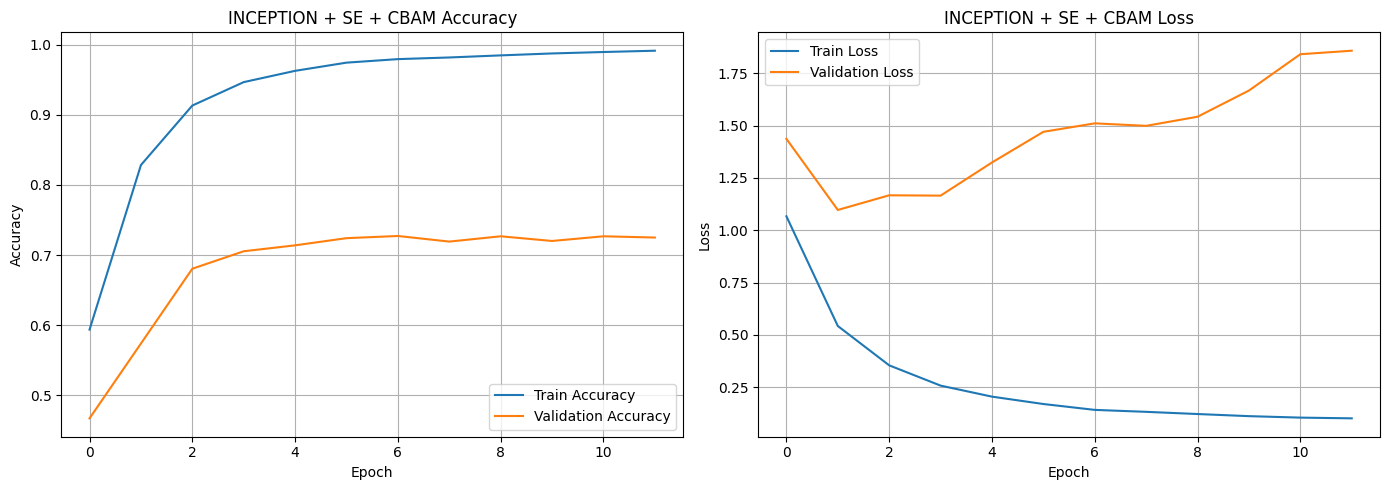


INCEPTION + SE + CBAM TEST RESULTS
Accuracy  : 0.8388
Precision : 0.8880
Recall    : 0.8415
Macro F1  : 0.8251

Classification Report
              precision    recall  f1-score   support

     WALKING     0.9812    0.8081    0.8863      1032
     JOGGING     1.0000    0.9498    0.9743       558
    UPSTAIRS     0.4458    0.9637    0.6096       303
  DOWNSTAIRS     0.9012    0.3274    0.4803       223
     SITTING     1.0000    1.0000    1.0000       133
    STANDING     1.0000    1.0000    1.0000       152

    accuracy                         0.8388      2401
   macro avg     0.8880    0.8415    0.8251      2401
weighted avg     0.9128    0.8388    0.8476      2401



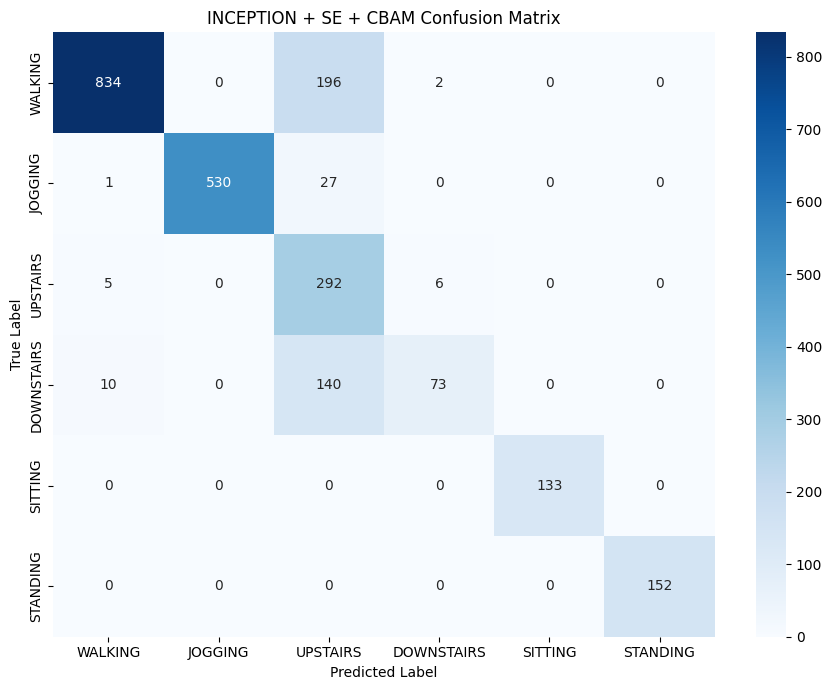


Final Results
                Model  Accuracy  Precision   Recall  Macro F1  Parameters
INCEPTION + SE + CBAM  0.838817   0.888035 0.841502   0.82507      204036


In [7]:

# ============================================================
# 21. TRAINING HISTORY
# ============================================================

plt.figure(figsize=(14, 5))

# Accuracy
plt.subplot(1, 2, 1)

plt.plot(
    history.history["accuracy"],
    label="Train Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("INCEPTION + SE + CBAM Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.grid(True)


# Loss
plt.subplot(1, 2, 2)

plt.plot(
    history.history["loss"],
    label="Train Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("INCEPTION + SE + CBAM Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# 22. LOAD BEST MODEL
# ============================================================

model = tf.keras.models.load_model(
    MODEL_PATH
)


# ============================================================
# 23. TEST PREDICTION
# ============================================================

y_prob = model.predict(
    X_test,
    batch_size=BATCH_SIZE,
    verbose=0
)

y_pred = np.argmax(
    y_prob,
    axis=1
)


# ============================================================
# 24. EVALUATION METRICS
# ============================================================

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)

print("\n================================")

print("INCEPTION + SE + CBAM TEST RESULTS")

print("================================")

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"Macro F1  : {f1:.4f}")


# ============================================================
# 25. CLASSIFICATION REPORT
# ============================================================

print("\nClassification Report")

print(
    classification_report(
        y_test,
        y_pred,
        labels=np.arange(N_CLASSES),
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)


# ============================================================
# 26. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(N_CLASSES)
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("INCEPTION + SE + CBAM Confusion Matrix")

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.tight_layout()

plt.show()


# ============================================================
# 27. SAVE RESULTS
# ============================================================

results = {

    "Model": "INCEPTION + SE + CBAM",

    "Accuracy": accuracy,

    "Precision": precision,

    "Recall": recall,

    "Macro F1": f1,

    "Parameters": model.count_params()

}

results_df = pd.DataFrame([results])

print("\nFinal Results")

print(results_df.to_string(index=False))
